# Evaluating Natural Language Explanations of Food Recommendation System XFoodRec Across Several LLMs

Authors: Junxuan Ling, Tianyi Liu, Anqi Zhou

# 0. Document Instructions

## 0.1. Git Version Control

After making modifications, please use Colab's function of "Save in Github to keep changes" (Github authorization required) to commit the changes to the repository (Your own branch if needed).

**NOTE**: When A modifies this notebook, but have not commited to Github, if B opens this notebook, they will see the Github old version.

## 0.2. Handle persistent data storage

Mount Google Drive instead of relying on Colab's temporary run-time storage.

**IMPORTANT:** Although Google Colab allows collaboration of the notebook, data and folders are originally in Junxuan's drive, this could cause issues when refering to the mounted directory path. To allow the code to work for all of us, (who's not junxuan) please create a **short-cut** of Junxuan's shared folder in our own Google Drive, path `MyDrive/`.

In [16]:
# load from drive
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0.3 Setup and data loading

Run the notebook from top to bottom. It does not parse the explanations again; it reads what Step 2 saved in 2.1e.

| File | Saved by | Used for |
|---|---|---|
| `explanation_lemmas.parquet` | Step 1 (preprocessing) | The 536 explanations with their persona, recipe and rank |
| `explanation_docs.spacy` | Step 2 (2.1e) | The parsed explanations, with each word's base form and whether it belongs to the recipe title |
| `user_factor_mentions.parquet` | Step 2 (2.1e) | Where each explanation names its persona's own values |

**Shared files:** everything in `processed/` is shared by the whole team. Rerunning the 2.1e cells of Step 2 overwrites these files for everyone. If a rule in Step 2 (2.0 or 2.1) changes, rerun Step 2 up to 2.1e before this notebook, otherwise this notebook reads the old results. The last cell here saves `transparency_levels.parquet` in the same folder.

In [17]:
%pip install -q spacy pyarrow

In [18]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
from spacy.tokens import DocBin

project_dir = Path("/content/drive/MyDrive/XFoodRec_Project_Data")
data_dir = project_dir / "raw"
processed_dir = project_dir / "processed"
persona_path = data_dir / "personas.json"

In [19]:
with persona_path.open("r", encoding="utf-8") as f:
    personas = json.load(f)

# every explanation: "<persona id>_rank_<rank>", with its persona, recipe and rank
explanation_index = pd.read_parquet(processed_dir / "explanation_lemmas.parquet")[
    ["recommendation_id", "persona_id", "recipe_id", "rank"]
]

# the parsed explanations saved in Step 2; a blank pipeline only reads them, nothing is parsed here
blank_nlp = spacy.blank("en")
explanation_docs = {
    doc.user_data["recommendation_id"]: doc
    for doc in DocBin().from_disk(processed_dir / "explanation_docs.spacy").get_docs(blank_nlp.vocab)
}

# where each explanation names its persona's own values (Step 2, 2.1e)
user_factor_mentions_df = pd.read_parquet(processed_dir / "user_factor_mentions.parquet")

assert set(explanation_docs) == set(explanation_index["recommendation_id"]), "explanation ids differ"

print("Explanations:", len(explanation_index))
print("Personas:", len(personas))
print(
    "User factor mentions:", len(user_factor_mentions_df),
    "in", user_factor_mentions_df["recommendation_id"].nunique(), "explanations",
)

Explanations: 536
Personas: 40
User factor mentions: 581 in 375 explanations


# 3. Transparency & Reasoning Analysis

## 3.1 Define the transparency levels

| Level | The explanation ... | Example |
|---|---|---|
| High | names one of the user's own values in a sentence that addresses the user | "This dish supports **your muscle gain** goal." / "It features **cauliflower** and cheese, aligning with **your** preferences." |
| Medium | names one of the user's own values, but not in a sentence that addresses the user; or addresses the user without naming any of their values | "It's great for **muscle gain**." / "It fits **your** dietary needs." |
| Low | does neither | "A classic comfort dish with rich flavors." |

- **The user's own values:** their goal, diets, allergies, health conditions, liked and disliked ingredients and favourite cuisines, as Step 2 found them in the explanation (same rules as 1.2d).
- **Addresses the user:** the sentence has a second-person word (you, your, yours, yourself), read from spaCy's grammatical person.
- Words in the recipe title are skipped for both, e.g. "Melt in **Your** Mouth Banana Bread".
- Score for Task 4: High = 2, Medium = 1, Low = 0.

Find the sentences that address the user

In [20]:
# a second-person word: you, your, yours, yourself (spaCy's grammatical person)
def is_second_person(token):
    return "2" in token.morph.get("Person")


# numbers of the sentences that address the user, skipping words of the recipe title
def addressed_sentences(doc):
    in_title = doc.user_data["in_title"]
    return sorted({
        sentence_number
        for sentence_number, sentence in enumerate(doc.sents)
        for token in sentence
        if is_second_person(token) and not in_title[token.i]
    })

In [21]:
# Sentences that address the user, for every explanation.
addressed = {
    recommendation_id: addressed_sentences(doc)
    for recommendation_id, doc in explanation_docs.items()
}

print("Explanations that address the user:", sum(bool(sentences) for sentences in addressed.values()))

Explanations that address the user: 508


Mark each user factor mention as explicit when its sentence addresses the user

In [22]:
# A mention is explicit when the same sentence addresses the user.
user_factor_mentions_df["explicit"] = [
    row.sentence in addressed[row.recommendation_id]
    for row in user_factor_mentions_df.itertuples()
]

display(
    user_factor_mentions_df
    .groupby("field")["explicit"]
    .agg(mentions="size", explicit="sum")
    .assign(percent_explicit=lambda table: (100 * table["explicit"] / table["mentions"]).round(1))
    .sort_values("mentions", ascending=False)
)

,mentions,explicit,percent_explicit
field,,,
liked_ingredient,273,204,74.7
dietary_goal,162,135,83.3
dietary_restriction,90,76,84.4
favorite_cuisine,49,47,95.9
health_condition,5,3,60.0
disliked_ingredient,2,1,50.0


## 3.2 Classify each explanation

In [23]:
LEVELS = ["High", "Medium", "Low"]
LEVEL_SCORES = {"High": 2, "Medium": 1, "Low": 0}


# the level of one explanation, from its user factor mentions and the sentences that address the user
def transparency_level(mentions, addressed_sentence_numbers):
    if mentions["explicit"].any():
        return "High"
    if len(mentions) or addressed_sentence_numbers:
        return "Medium"
    return "Low"

In [24]:
mentions_by_explanation = dict(tuple(user_factor_mentions_df.groupby("recommendation_id")))
no_mentions = user_factor_mentions_df.iloc[0:0]

transparency_rows = []
for row in explanation_index.itertuples():
    mentions = mentions_by_explanation.get(row.recommendation_id, no_mentions)
    level = transparency_level(mentions, addressed[row.recommendation_id])

    transparency_rows.append({
        "recommendation_id": row.recommendation_id,
        "persona_id": row.persona_id,
        "recipe_id": row.recipe_id,
        "rank": row.rank,
        "level": level,
        "score": LEVEL_SCORES[level],
        "addresses_user": bool(addressed[row.recommendation_id]),
        "factor_mentions": len(mentions),
        "explicit_factor_mentions": int(mentions["explicit"].sum()),
        # the user's own values named in a sentence that addresses the user
        "explicit_factors": sorted(set(mentions.loc[mentions["explicit"], "value"])),
    })

transparency_df = pd.DataFrame(transparency_rows)

Inspect two explanations of each level

In [25]:
# Show two explanations per level with the user's values named in them.
for level in LEVELS:
    print(f"===== {level}")
    for row in transparency_df[transparency_df["level"] == level].head(2).itertuples():
        print(f"{row.recommendation_id} | explicit factors: {row.explicit_factors} | addresses the user: {row.addresses_user}")
        print("  ", explanation_docs[row.recommendation_id].text)

===== High
user_01_rank_01 | explicit factors: ['chickpea', 'muscle gain'] | addresses the user: True
   Chickpeas With Spinach (Greek) is a fantastic choice packed with protein, aligning perfectly with your muscle gain goal. The inclusion of chickpeas and spinach not only satisfies your taste for legumes but also provides essential nutrients for recovery and growth.
user_01_rank_03 | explicit factors: ['lentil', 'muscle gain'] | addresses the user: True
   Egyptian Red Lentil Soup is rich in protein and fiber, ideal for your muscle gain goal. It features lentils, which you enjoy, and provides a warming, nutritious meal that can support your active lifestyle.
===== Medium
user_01_rank_02 | explicit factors: [] | addresses the user: True
   Refried Beans offers a high protein content, making it a great option for muscle gain. The use of black beans ensures a hearty meal that aligns with your preferences, while being low in fat.
user_01_rank_04 | explicit factors: [] | addresses the user

## 3.3 Distribution of transparency levels

In [26]:
level_counts = transparency_df["level"].value_counts().reindex(LEVELS, fill_value=0)
level_summary = level_counts.rename("explanations").to_frame()
level_summary["percent"] = (100 * level_summary["explanations"] / len(transparency_df)).round(1)
display(level_summary)
print("Mean score:", round(transparency_df["score"].mean(), 2))

,explanations,percent
level,,
High,320,59.7
Medium,202,37.7
Low,14,2.6


Mean score: 1.57


## 3.4 Compare across persona types

| Persona type | Groups |
|---|---|
| Dietary goal | the goal in the profile |
| Dietary restriction, food allergy, health condition | yes / no: at least one value selected in the profile (free-text notes are not counted) |
| Gender | as in the profile |
| Age group | under 18, 18-39, 40-59, 60+ |

Shares are over explanations; the number of personas in each group is shown because the explanations of one persona are not independent. Statistical tests are part of Task 4.

In [27]:
AGE_GROUPS = [(17, "under 18"), (39, "18-39"), (59, "40-59"), (200, "60+")]


# the age group of one persona
def age_group(age):
    return next(label for upper, label in AGE_GROUPS if age <= upper)


# yes / no: whether the profile has at least one selected value in this field
def has_selected(dietary_profile, field):
    return "yes" if dietary_profile[field]["selected"] else "no"


# one row of persona characteristics per persona
def persona_types(personas):
    rows = []
    for persona in personas:
        profile = persona["profile"]
        dietary_profile = profile["dietaryProfile"]
        rows.append({
            "persona_id": persona["id"],
            "dietary goal": profile["dietary_goal"],
            "dietary restriction": has_selected(dietary_profile, "dietaryRestrictions"),
            "food allergy": has_selected(dietary_profile, "foodAllergies"),
            "health condition": has_selected(dietary_profile, "healthConditions"),
            "gender": profile["gender"],
            "age group": age_group(profile["age"]),
        })
    table = pd.DataFrame(rows)
    # keep the age groups in age order, not in alphabetical order
    table["age group"] = pd.Categorical(table["age group"], categories=[label for _, label in AGE_GROUPS], ordered=True)
    return table


# level shares and mean score for every group of one persona type
def level_shares(table, persona_type):
    grouped = table.groupby(persona_type, observed=True)
    shares = (
        pd.crosstab(table[persona_type], table["level"], normalize="index")
        .reindex(columns=LEVELS, fill_value=0) * 100
    ).round(1)
    shares.insert(0, "explanations", grouped.size())
    shares.insert(0, "personas", grouped["persona_id"].nunique())
    shares["mean score"] = grouped["score"].mean().round(2)
    return shares

In [28]:
PERSONA_TYPES = ["dietary goal", "dietary restriction", "food allergy", "health condition", "gender", "age group"]

persona_type_df = persona_types(personas)
transparency_by_persona = transparency_df.merge(persona_type_df, on="persona_id", how="left", validate="many_to_one")

comparison = pd.concat(
    {persona_type: level_shares(transparency_by_persona, persona_type) for persona_type in PERSONA_TYPES},
    names=["persona type", "group"],
)
display(comparison)

level                                   personas  explanations  High  Medium  \
persona type        group                                                      
dietary goal        Energy Boost               6            83  66.3    31.3   
                    Maintenance                8           107  57.9    39.3   
                    Medical Management        14           186  51.6    45.2   
                    Muscle Gain                5            69  56.5    43.5   
                    Weight Loss                7            91  74.7    22.0   
dietary restriction no                         8           111  68.5    27.9   
                    yes                       32           425  57.4    40.2   
food allergy        no                        32           431  58.2    39.0   
                    yes                        8           105  65.7    32.4   
health condition    no                        10           137  64.2    33.6   
                    yes                       30           399  58.1    39.1   
gender              Female                    20           268  59.3    38.4   
                    Male                      19           255  58.8    38.0   
                    Non-binary                 1            13  84.6    15.4   
age group           under 18                   3            40  50.0    50.0   
                    18-39                     21           284  63.0    35.2   
                    40-59                     12           162  63.0    33.3   
                    60+                        4            50  38.0    56.0   

level                                   Low  mean score  
persona type        group                                
dietary goal        Energy Boost        2.4        1.64  
                    Maintenance         2.8        1.55  
                    Medical Management  3.2        1.48  
                    Muscle Gain         0.0        1.57  
                    Weight Loss         3.3        1.71  
dietary restriction no                  3.6        1.65  
                    yes                 2.4        1.55  
food allergy        no                  2.8        1.55  
                    yes                 1.9        1.64  
health condition    no                  2.2        1.62  
                    yes                 2.8        1.55  
gender              Female              2.2        1.57  
                    Male                3.1        1.56  
                    Non-binary          0.0        1.85  
age group           under 18            0.0        1.50  
                    18-39               1.8        1.61  
                    40-59               3.7        1.59  
                    60+                 6.0        1.32

Share of each level by persona group (%)

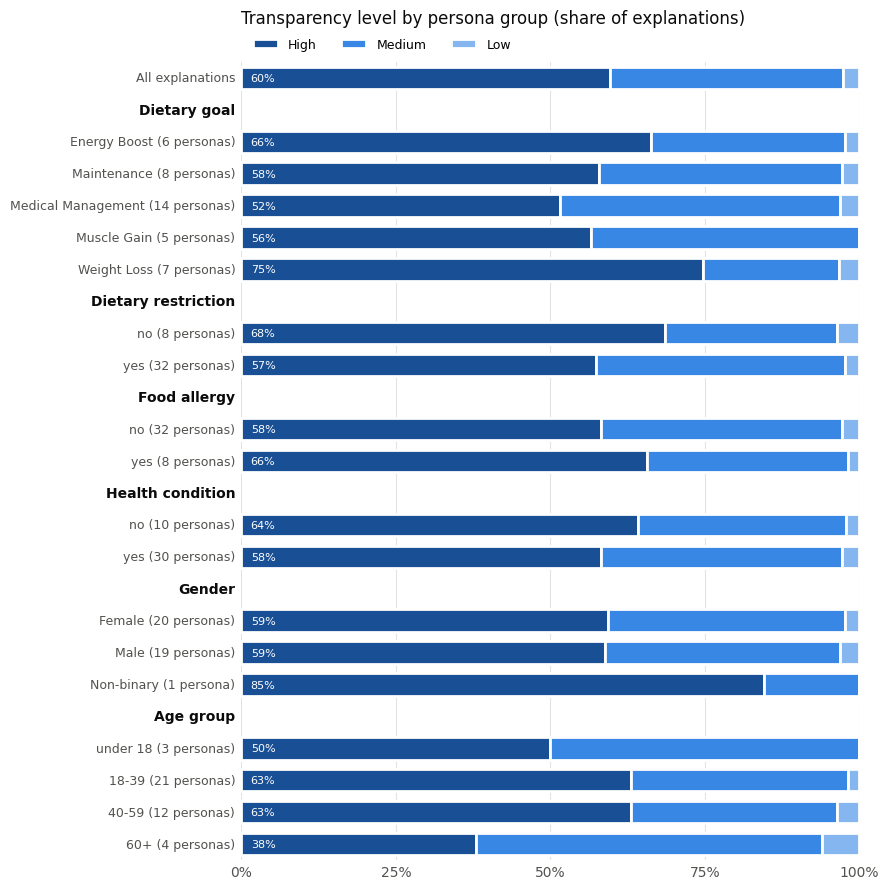

In [29]:
# One blue from light to dark, because the levels are ordered (Low < Medium < High).
LEVEL_COLORS = {"High": "#184f95", "Medium": "#3987e5", "Low": "#86b6ef"}
TEXT_COLOR, MUTED_COLOR, GRID_COLOR = "#0b0b0b", "#52514e", "#e4e3df"


# the rows of the chart: all explanations first, then each persona type with its groups
def chart_rows(comparison, overall):
    rows = [("All explanations", overall, False)]
    for persona_type in PERSONA_TYPES:
        rows.append((persona_type.capitalize(), None, True))
        for group, values in comparison.loc[persona_type].iterrows():
            personas = int(values["personas"])
            rows.append((f"{group} ({personas} persona{'s' if personas != 1 else ''})", values, False))
    return rows


overall = transparency_df["level"].value_counts(normalize=True).reindex(LEVELS, fill_value=0) * 100
rows = chart_rows(comparison, overall)

fig, ax = plt.subplots(figsize=(9, 0.32 * len(rows) + 1))
for y, (label, values, is_header) in enumerate(rows):
    if is_header:
        ax.text(-1, y, label, ha="right", va="center", fontsize=10, fontweight="bold", color=TEXT_COLOR)
        continue
    left = 0
    for level in LEVELS:
        width = values[level]
        # a white edge leaves a small gap between the segments
        ax.barh(y, width, left=left, height=0.7, color=LEVEL_COLORS[level], edgecolor="white", linewidth=2,
                label=level if y == 0 else None)
        # label only the High share, the main measure
        if level == "High" and width >= 8:
            ax.text(left + 1.5, y, f"{width:.0f}%", ha="left", va="center", fontsize=8, color="white")
        left += width
    ax.text(-1, y, label, ha="right", va="center", fontsize=9, color=MUTED_COLOR)

ax.set_yticks([])
ax.set_ylim(len(rows) - 0.5, -0.5)
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"], color=MUTED_COLOR)
ax.xaxis.grid(True, color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left", "bottom"]:
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
ax.set_title("Transparency level by persona group (share of explanations)", loc="left", color=TEXT_COLOR, pad=28)
ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 3.5 Save the levels for Task 4

In [30]:
# One row per explanation: its level, score and the evidence behind it.
transparency_levels_path = processed_dir / "transparency_levels.parquet"
transparency_df.to_parquet(transparency_levels_path, index=False)
print("Saved:", len(transparency_df), "explanations ->", transparency_levels_path)

Saved: 536 explanations -> /content/drive/MyDrive/XFoodRec_Project_Data/processed/transparency_levels.parquet
